# Import software libraries

In [1]:
# Import required libraries.
import sys                          # Read system parameters.
import numpy as np                  # Work with multi-dimensional arrays.
import pandas as pd                 # Manipulate and analyze data.
import matplotlib                   # Create and format charts.
import matplotlib.pyplot as plt  
import seaborn as sns               # Make charting easier.

# Summarize software libraries used.
print('Libraries used in this project:')
print('- NumPy {}'.format(np.__version__))
print('- Python {}'.format(sys.version))
print('- pandas {}'.format(pd.__version__))
print('- Matplotlib {}'.format(matplotlib.__version__))
print('- Seaborn {}'.format(sns.__version__))

Libraries used in this project:
- NumPy 1.19.2
- Python 3.7.6 | packaged by conda-forge | (default, Mar 23 2020, 23:03:20) 
[GCC 7.3.0]
- pandas 1.1.3
- Matplotlib 3.3.2
- Seaborn 0.11.0


# Read and examine the data

In [7]:
# Read the data that was put through the ETL process in Course 2 of the CDSP Specialization. 
df = pd.read_pickle('/home/jovyan/work/Project/data/online_history_cleaned.pickle')



# Preview the first five rows of the data.

df.head(5)

,Invoice,StockCode,Quantity,InvoiceDate,Price,CustomerID,Country,TotalAmount,Description
0,536365,85123A,6,2010-12-01 08:26:00,2.55,u1785,United Kingdom,15.30,CREAM HANGING HEART T-LIGHT HOLDER
1,536367,84879,32,2010-12-01 08:34:00,1.69,u13047,United Kingdom,54.08,ASSORTED COLOUR BIRD ORNAMENT
2,536373,85123A,6,2010-12-01 09:02:00,2.55,u1785,United Kingdom,15.30,CREAM HANGING HEART T-LIGHT HOLDER
3,536375,85123A,6,2010-12-01 09:32:00,2.55,u1785,United Kingdom,15.30,CREAM HANGING HEART T-LIGHT HOLDER
4,536378,20725,10,2010-12-01 09:37:00,1.65,u14688,United Kingdom,16.50,LUNCH BAG RED RETROSPOT


In [8]:
# Get the shape of the data.

df.shape

(15206, 9)

In [9]:
# Get the data types for every column in the DataFrame.

df.dtypes

Invoice                object
StockCode              object
Quantity                int64
InvoiceDate    datetime64[ns]
Price                 float64
CustomerID             object
Country                object
TotalAmount           float64
Description            object
dtype: object

# Generate summary statistics for all of the data

In [10]:
# Get a DataFrame of summary statistics that describe the data, including mean, median, standard deviation, etc.
# Be sure to include all variables, including categorical ones.

df.describe(include='all')

,Invoice,StockCode,Quantity,InvoiceDate,Price,CustomerID,Country,TotalAmount,Description
count,15206,15206,15206.000000,15206,15194.000000,12435,15206,15194.000000,15206
unique,8315,10,NaN,8022,NaN,2473,1,NaN,10
top,536876,85123A,NaN,2011-05-10 15:07:00,NaN,u17841,United Kingdom,NaN,CREAM HANGING HEART T-LIGHT HOLDER
freq,10,2163,NaN,10,NaN,171,15206,NaN,2163
first,NaN,NaN,NaN,2010-12-01 08:26:00,NaN,NaN,NaN,NaN,NaN
last,NaN,NaN,NaN,2011-12-09 12:31:00,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,16.775483,NaN,4.164267,NaN,NaN,40.705153,NaN
std,NaN,NaN,79.496270,NaN,4.377605,NaN,NaN,132.142503,NaN
min,NaN,NaN,1.000000,NaN,0.400000,NaN,NaN,0.550000,NaN
25%,NaN,NaN,2.000000,NaN,1.650000,NaN,NaN,8.850000,NaN


# Plot a bar chart for the average price per item

<AxesSubplot:xlabel='Description'>

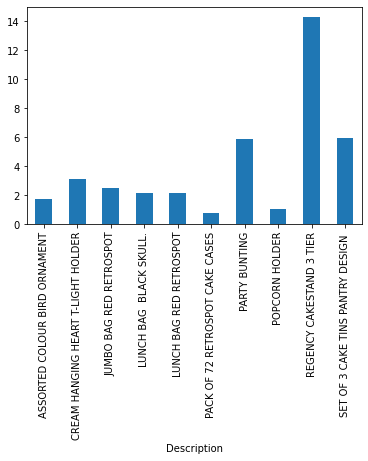

In [12]:
# Plot the average price per item using a bar chart.
# Make sure the average price is on one axis, and each distinct item description is on the other axis.

df.groupby('Description')['Price'].mean().plot(kind='bar')






# Explore the distribution of the numeric variable `Price`

In [13]:
# Get a DataFrame of summary statistics for numeric variables only.

df_summary = df.describe()
df_summary

,Quantity,Price,TotalAmount
count,15206.000000,15194.000000,15194.000000
mean,16.775483,4.164267,40.705153
std,79.496270,4.377605,132.142503
min,1.000000,0.400000,0.550000
25%,2.000000,1.650000,8.850000
50%,6.000000,2.550000,16.500000
75%,12.000000,4.950000,30.360000
max,4300.000000,32.040000,4921.500000


<AxesSubplot:xlabel='Price'>

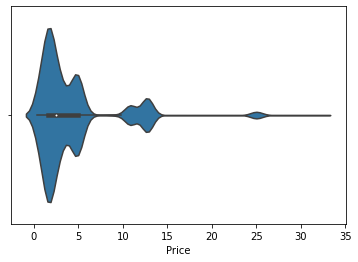

In [15]:
# Generate a violin plot for the "Price" variable.
# Decorate and style the plot however you think is best.

sns.violinplot(x=df['Price'])

# Visualize correlations between numeric variables

In [16]:
# Generate a correlation matrix between all numeric variables.

df.corr(method='pearson')



,Quantity,Price,TotalAmount
Quantity,1.000000,-0.088356,0.745641
Price,-0.088356,1.000000,0.109054
TotalAmount,0.745641,0.109054,1.000000


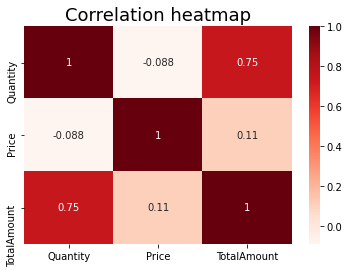

In [17]:
# Visualize the correlations with a heatmap.

plt.figure(figsize=(6,4))
sns.heatmap(df.corr(method='pearson'), annot=True, cmap='Reds')
plt.title('Correlation heatmap',
          fontsize=18)
plt.show()



# Transform skewed variables

array([[<AxesSubplot:title={'center':'Quantity'}>,
        <AxesSubplot:title={'center':'Price'}>],
       [<AxesSubplot:title={'center':'TotalAmount'}>, <AxesSubplot:>]],
      dtype=object)

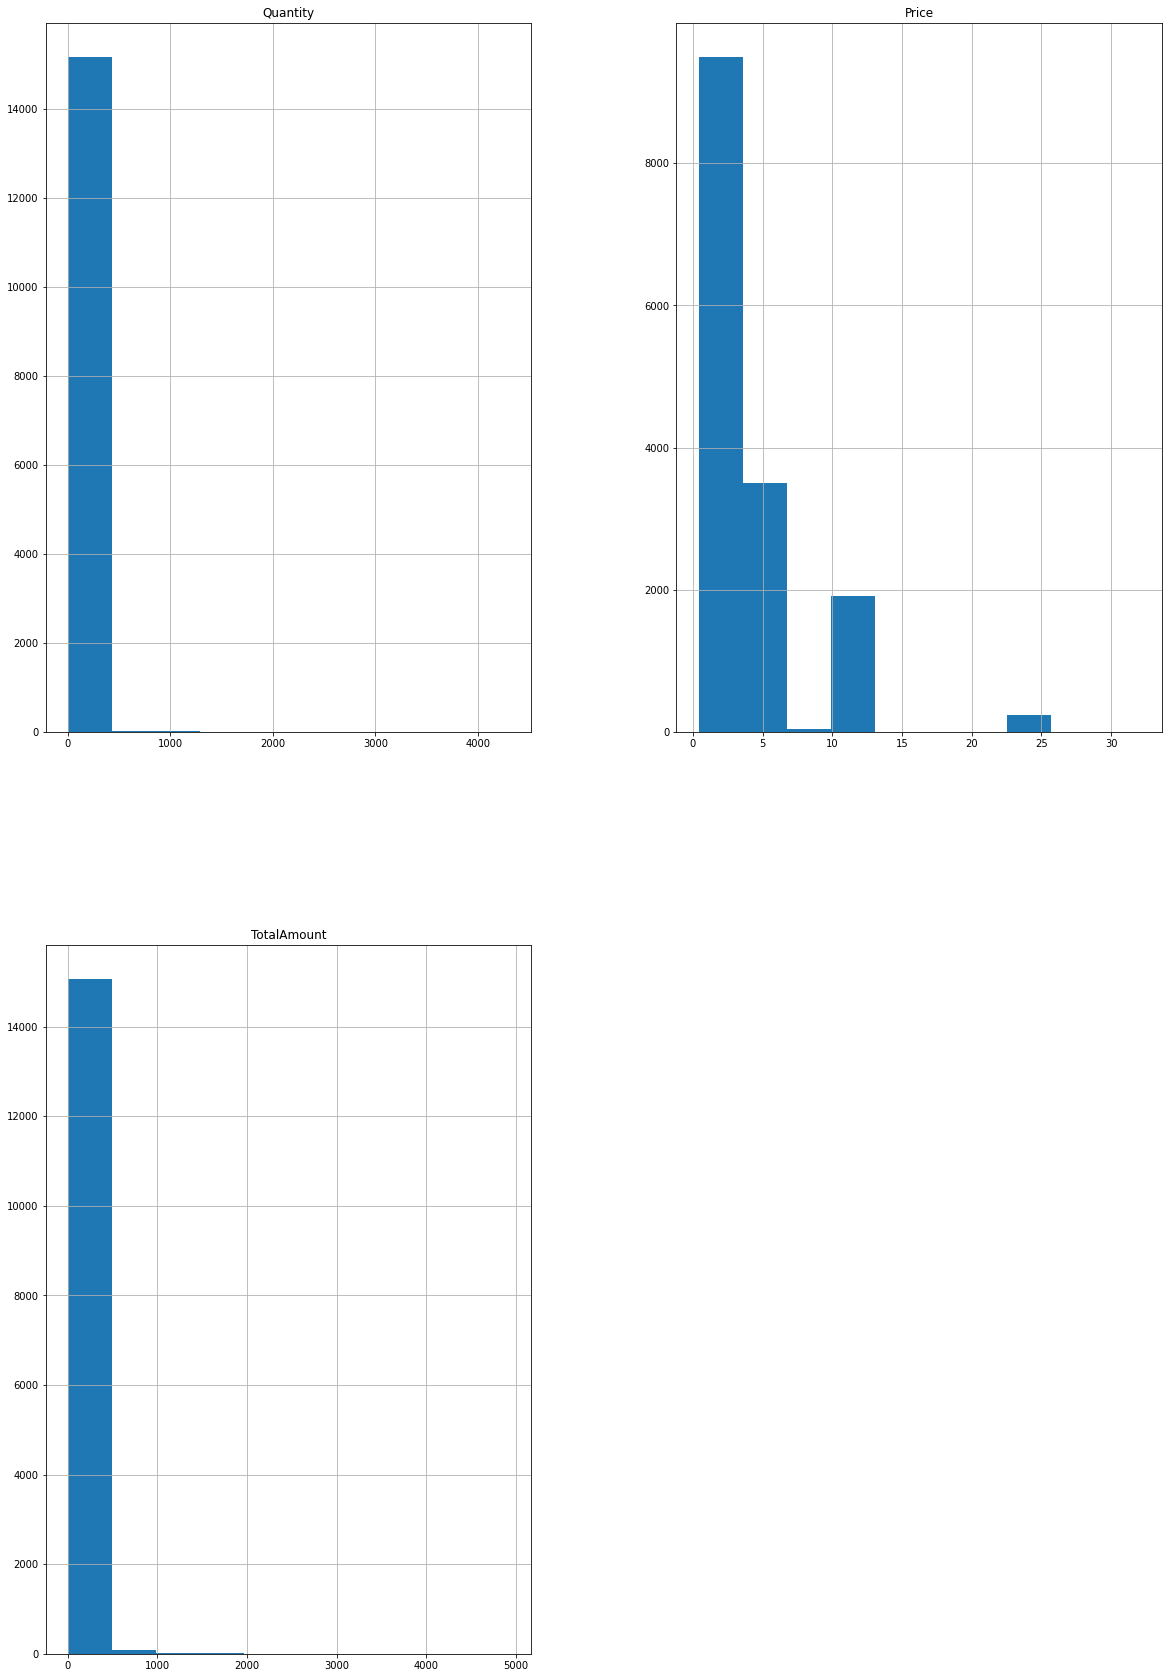

In [18]:
# Plot histograms for the original distributions of all numeric variables.
df.hist(figsize=(20,30))


<AxesSubplot:xlabel='log_price', ylabel='Count'>

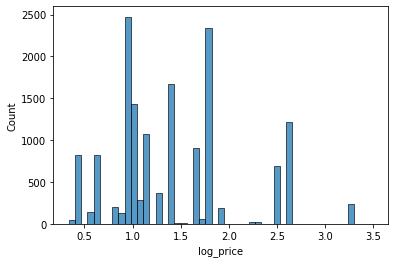

In [20]:
# Plot the log transformation of "Price".

df['log_price'] = np.log1p(df['Price'])
sns.histplot(df['log_price'])

<AxesSubplot:xlabel='log_Quantity', ylabel='Count'>

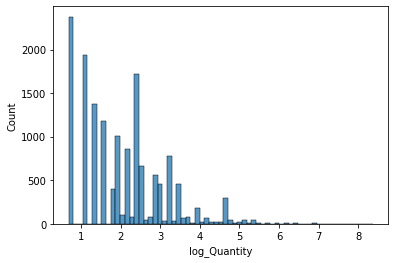

In [21]:
# Plot the log transformation of "Quantity".
df['log_Quantity'] = np.log1p(df['Quantity'])
sns.histplot(df['log_Quantity'])



<AxesSubplot:xlabel='log_TotalAmount', ylabel='Count'>

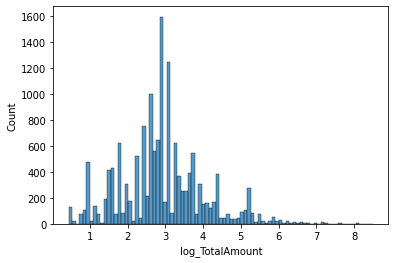

In [22]:
# Plot the log transformation of "TotalAmount".

df['log_TotalAmount'] = np.log1p(df['TotalAmount'])
sns.histplot(df['log_TotalAmount'])


# Analyze time series data

In [24]:
# Obtain the number of invoices by month.
# Create a month column
df['month'] = df['InvoiceDate'].dt.month_name()



# Print the number of invoices by month.

df.groupby('month')['Quantity'].count()


month
April        1140
August       1169
December     1498
February      956
January       923
July         1227
June         1203
March        1345
May          1384
November     1726
October      1257
September    1378
Name: Quantity, dtype: int64

<AxesSubplot:xlabel='month'>

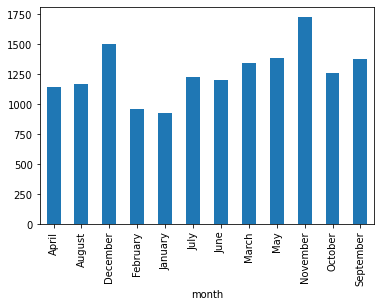

In [25]:
# Use a bar chart to plot the number of invoices by month.
df.groupby('month')['Quantity'].count().plot(kind='bar')




# Identify and handle missing data

In [26]:
# Identify any missing data for all variables.

df.isna().sum()

Invoice               0
StockCode             0
Quantity              0
InvoiceDate           0
Price                12
CustomerID         2771
Country               0
TotalAmount          12
Description           0
log_price            12
log_Quantity          0
log_TotalAmount      12
month                 0
dtype: int64

In [28]:
# Print the current shape of the data.

df.shape

# Remove rows of data where "CustomerID" is unknown.
df = df.dropna(subset=['CustomerID'])


# Print the new shape of the data.

df.shape

(12435, 13)

In [29]:
# Fill in N/A values for "Price" and "TotalAmount" with 0.

df[['Price', 'TotalAmount']] = df[['Price', 'TotalAmount']].fillna(0)


# Confirm there are no longer any missing values.
df.isna().sum()


Invoice            0
StockCode          0
Quantity           0
InvoiceDate        0
Price              0
CustomerID         0
Country            0
TotalAmount        0
Description        0
log_price          1
log_Quantity       0
log_TotalAmount    1
month              0
dtype: int64

# One-hot encode the `Description` variable

In [ ]:
# One-hot encode the "Description" variable with dummy variables for each unique description.
# Prefix each dummy variable name with "Description".



# Preview the first five rows of the DataFrame.



In [ ]:
# Concatenate the new encoded columns with the main DataFrame.



# Drop the original "Description" variable.



In [ ]:
# Preview the first five rows of the data.



# Identify and remove columns with low variance

In [30]:
# Obtain the standard deviation of each variable.
df.std(numeric_only=True)


Quantity            77.436253
Price                3.506381
TotalAmount        132.092738
log_price            0.600163
log_Quantity         1.059758
log_TotalAmount      1.096991
dtype: float64

In [31]:
# Define a standard deviation threshold of 0.26.

threshold = 0.26

# Identify any columns that are lower than the threshold.
std_values = df.std(numeric_only=True)
cols_to_drop = std_values[std_values < threshold].index.tolist()


# Print the column(s) that will be dropped.
print("Columns to be dropped:", cols_to_drop)


Columns to be dropped: []


In [ ]:
# Drop the column(s) that have low standard deviation from the main dataset.



# Preview the first five rows of data.



# Generate box plots for each numeric variable

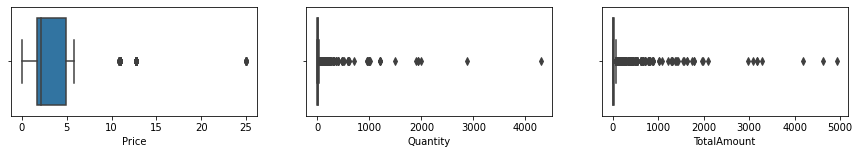

In [40]:
# Draw box plots for each numeric variable.
fig, axes = plt.subplots(1, 3, figsize=(15, 2))

sns.boxplot(ax=axes[0], x=df['Price'])

sns.boxplot(ax=axes[1], x=df['Quantity'])

sns.boxplot(ax=axes[2], x=df['TotalAmount'])

plt.show();





# Identify and remove outliers

In [ ]:
# This function returns the lower and upper bounds of a numeric input variable.

def calc_outliers(var):
    q3 = np.percentile(var, 75) 
    q1 = np.percentile(var, 25)

    iqr = 1.5 * (q3 - q1)

    lb = q1 - iqr
    ub = q3 + iqr

    print('Lower bound of outliers:', round(lb, 2), '\nUpper bound of outliers:', round(ub, 2))
    
    return lb, ub

In [ ]:
# Identify the shape of the data before removing outliers.




In [ ]:
# Call the calc_outliers() function iteratively for each numeric variable.
# For each variable:
#     Remove the outliers that are higher than the upper bounds.
#     Remove the variables that are lower than the lower bounds.
# As you iterate through each variable, print the shape of the data after the outliers for that variable are removed.







# Save the final dataset as a pickle file

In [ ]:
# Save the final dataset as a pickle file named online_history_cleaned_final.pickle.

